#
---
#<center>**Reducing Inventory Waste in Grocery Stores**<center/>     
##### <center>**Anisha Penikalapati | Kritika Rajpal | Mary Penta Reddy | Suha Fasih | Zawwar Rizvi**<center/>

---

## **<ins>Data Pipeline</ins>**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
# Load data
url = "https://drive.google.com/uc?export=download&id=1mtKaQBoUcGrpH2ppFvM6JPbYfzYeu_4E"
df = pd.read_csv(url)

#### **Dataset Filtering and Cleaning**

In [3]:
# Removed ID Columns & Unnecessary Date Columns
df = df.drop(columns=['record_id', 'product_id', 'store_id', 'supplier_id', 'day_of_week', 'is_weekend', 'month'])

These columns do not contribute to prediction and were not needed for modeling.

In [4]:
df

,product_name,category,region,transaction_date,expiration_date,shelf_life_days,days_remaining_at_purchase,storage_temp,temp_deviation,base_price,...,selling_price,units_sold,units_wasted,waste_pct,revenue,waste_cost,profit,profit_margin_pct,supplier_score,is_promoted
0,Donuts,Bakery,West,2024-09-25,2024-09-29,4,4,21.0,1.0,2.60,...,2.60,138,20,12.7,358.80,24.40,166.04,46.3,9,0
1,Sausages,Meat,Southwest,2023-04-14,2023-04-21,9,7,0.7,0.3,8.25,...,8.25,251,102,28.9,2070.75,426.36,595.21,28.7,6,0
2,Bagels,Bakery,Midwest,2024-10-25,2024-10-27,2,2,21.3,1.3,4.12,...,1.28,483,0,0.0,618.24,0.00,-405.72,-65.6,9,0
3,Vaccines,Pharmaceuticals,Midwest,2023-11-29,2024-02-17,87,80,8.0,3.0,209.56,...,209.56,477,0,0.0,99960.12,0.00,57988.89,58.0,6,0
4,Fresh Pasta,Ready_to_Eat,West,2023-08-06,2023-08-09,4,3,3.5,0.5,6.86,...,5.28,391,0,0.0,2064.48,0.00,879.75,42.6,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Dips,Deli,Southwest,2024-12-22,2024-12-27,5,5,3.5,0.5,12.10,...,12.10,149,0,0.0,1802.90,0.00,1063.86,59.0,10,0
99996,Frozen Dinners,Frozen_Meals,Midwest,2023-11-28,2024-06-06,204,191,-21.1,1.1,13.60,...,13.60,0,212,100.0,0.00,1392.84,-1392.84,0.0,8,0
99997,Chicken,Meat,Southwest,2023-06-15,2023-06-21,9,6,1.8,0.8,12.28,...,12.28,264,208,44.1,3241.92,1312.48,263.60,8.1,10,1
99998,Eye Drops,Pharmaceuticals,West,2024-12-14,2026-03-03,581,444,4.6,0.4,320.12,...,320.12,0,251,100.0,0.00,51919.35,-51919.35,0.0,6,0


In [5]:
# Changing the transaction dates and expiration dates from strings to DateTime

from datetime import datetime
date_format = "%Y-%m-%d"
df['transaction_date'] = pd.to_datetime(df['transaction_date'])
df['expiration_date'] = pd.to_datetime(df['expiration_date'])
df.dtypes

,0
product_name,object
category,object
region,object
transaction_date,datetime64[ns]
expiration_date,datetime64[ns]
shelf_life_days,int64
days_remaining_at_purchase,int64
storage_temp,float64
temp_deviation,float64
base_price,float64


- These columns were converted from strings to datetime format so that it can be easier to sort and split the data into train/validate/test sections based on time.

In [6]:
# Converting is_promoted type to boolean so that it is easier to read
df['is_promoted'] = df['is_promoted'].astype('bool')
df

,product_name,category,region,transaction_date,expiration_date,shelf_life_days,days_remaining_at_purchase,storage_temp,temp_deviation,base_price,...,selling_price,units_sold,units_wasted,waste_pct,revenue,waste_cost,profit,profit_margin_pct,supplier_score,is_promoted
0,Donuts,Bakery,West,2024-09-25,2024-09-29,4,4,21.0,1.0,2.60,...,2.60,138,20,12.7,358.80,24.40,166.04,46.3,9,False
1,Sausages,Meat,Southwest,2023-04-14,2023-04-21,9,7,0.7,0.3,8.25,...,8.25,251,102,28.9,2070.75,426.36,595.21,28.7,6,False
2,Bagels,Bakery,Midwest,2024-10-25,2024-10-27,2,2,21.3,1.3,4.12,...,1.28,483,0,0.0,618.24,0.00,-405.72,-65.6,9,False
3,Vaccines,Pharmaceuticals,Midwest,2023-11-29,2024-02-17,87,80,8.0,3.0,209.56,...,209.56,477,0,0.0,99960.12,0.00,57988.89,58.0,6,False
4,Fresh Pasta,Ready_to_Eat,West,2023-08-06,2023-08-09,4,3,3.5,0.5,6.86,...,5.28,391,0,0.0,2064.48,0.00,879.75,42.6,6,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Dips,Deli,Southwest,2024-12-22,2024-12-27,5,5,3.5,0.5,12.10,...,12.10,149,0,0.0,1802.90,0.00,1063.86,59.0,10,False
99996,Frozen Dinners,Frozen_Meals,Midwest,2023-11-28,2024-06-06,204,191,-21.1,1.1,13.60,...,13.60,0,212,100.0,0.00,1392.84,-1392.84,0.0,8,False
99997,Chicken,Meat,Southwest,2023-06-15,2023-06-21,9,6,1.8,0.8,12.28,...,12.28,264,208,44.1,3241.92,1312.48,263.60,8.1,10,True
99998,Eye Drops,Pharmaceuticals,West,2024-12-14,2026-03-03,581,444,4.6,0.4,320.12,...,320.12,0,251,100.0,0.00,51919.35,-51919.35,0.0,6,False


#### **Dataset Pre-processing**

##### **Data Leakage Check**

In [7]:
# Leakage check — class means for all suspected columns
# ratio ~ 1.0 means safe; ratio > 5 or < 0.2 means leakage
print(f"{'column':25s} {'class0':>10s} {'class1':>10s} {'ratio':>8s}")
print("-" * 55)
for col in ['units_wasted', 'waste_pct', 'waste_cost', 'profit',
            'revenue', 'profit_margin_pct', 'units_sold',
            'spoilage_risk', 'selling_price', 'markdown_applied',
            'discount_pct', 'days_until_expiry', 'distribution_hours']:
    means = df.groupby('was_spoiled')[col].mean()
    ratio = means[1] / max(means[0], 1e-9)
    print(f"{col:25s} {means[0]:10.3f} {means[1]:10.3f} {ratio:8.2f}")

column                        class0     class1    ratio
-------------------------------------------------------
units_wasted                  42.303     92.262     2.18
waste_pct                     18.865     38.033     2.02
waste_cost                  1431.383   2464.519     1.72
profit                      1121.003   -541.201    -0.48
revenue                     6184.615   4780.091     0.77
profit_margin_pct             17.683     -4.375    -0.25
units_sold                   212.760    161.716     0.76
spoilage_risk                  0.192      0.209     1.09
selling_price                 34.002     35.825     1.05
markdown_applied               0.293      0.361     1.23
discount_pct                   0.097      0.118     1.22
days_until_expiry             54.879     53.830     0.98
distribution_hours            37.744     39.169     1.04


##### **Removing Features that could Leak Data**

In [8]:
# Removed Columns that could Leak Data and reveal information that would not be available before spoilage occurs
df = df.drop(columns=['units_wasted', 'waste_pct', 'waste_cost', 'profit', 'revenue', 'profit_margin_pct', 'spoilage_risk', 'units_sold', 'selling_price', 'markdown_applied', 'discount_pct','days_until_expiry', 'expiration_date'])
df

,product_name,category,region,transaction_date,shelf_life_days,days_remaining_at_purchase,storage_temp,temp_deviation,base_price,cost_price,...,daily_demand,demand_variability,temp_abuse_events,distribution_hours,handling_score,packaging_score,was_spoiled,quality_grade,supplier_score,is_promoted
0,Donuts,Bakery,West,2024-09-25,4,4,21.0,1.0,2.60,1.22,...,54,0.35,0,41.5,9,10,0,A,9,False
1,Sausages,Meat,Southwest,2023-04-14,9,7,0.7,0.3,8.25,4.18,...,55,0.35,0,38.7,8,8,0,A,6,False
2,Bagels,Bakery,Midwest,2024-10-25,2,2,21.3,1.3,4.12,2.12,...,331,0.35,0,54.1,4,8,0,B,9,False
3,Vaccines,Pharmaceuticals,Midwest,2023-11-29,87,80,8.0,3.0,209.56,87.99,...,7,0.38,0,70.1,5,9,0,B,6,False
4,Fresh Pasta,Ready_to_Eat,West,2023-08-06,4,3,3.5,0.5,6.86,3.03,...,169,0.25,0,64.9,5,6,0,C,6,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Dips,Deli,Southwest,2024-12-22,5,5,3.5,0.5,12.10,4.96,...,53,0.18,1,34.3,10,10,0,A,10,False
99996,Frozen Dinners,Frozen_Meals,Midwest,2023-11-28,204,191,-21.1,1.1,13.60,6.57,...,0,0.46,0,55.8,6,7,1,B,8,False
99997,Chicken,Meat,Southwest,2023-06-15,9,6,1.8,0.8,12.28,6.31,...,65,0.21,0,52.3,6,7,0,B,10,True
99998,Eye Drops,Pharmaceuticals,West,2024-12-14,581,444,4.6,0.4,320.12,206.85,...,0,0.29,0,11.4,8,9,0,A,6,False


##### **Removing Irrelevant Features**

In [9]:
# Removed irrelevant column that does not help predict spoilage
df = df.drop(columns=['distribution_hours'])
df

,product_name,category,region,transaction_date,shelf_life_days,days_remaining_at_purchase,storage_temp,temp_deviation,base_price,cost_price,...,spoilage_sensitivity,daily_demand,demand_variability,temp_abuse_events,handling_score,packaging_score,was_spoiled,quality_grade,supplier_score,is_promoted
0,Donuts,Bakery,West,2024-09-25,4,4,21.0,1.0,2.60,1.22,...,0.50,54,0.35,0,9,10,0,A,9,False
1,Sausages,Meat,Southwest,2023-04-14,9,7,0.7,0.3,8.25,4.18,...,0.90,55,0.35,0,8,8,0,A,6,False
2,Bagels,Bakery,Midwest,2024-10-25,2,2,21.3,1.3,4.12,2.12,...,0.50,331,0.35,0,4,8,0,B,9,False
3,Vaccines,Pharmaceuticals,Midwest,2023-11-29,87,80,8.0,3.0,209.56,87.99,...,0.85,7,0.38,0,5,9,0,B,6,False
4,Fresh Pasta,Ready_to_Eat,West,2023-08-06,4,3,3.5,0.5,6.86,3.03,...,0.90,169,0.25,0,5,6,0,C,6,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Dips,Deli,Southwest,2024-12-22,5,5,3.5,0.5,12.10,4.96,...,0.75,53,0.18,1,10,10,0,A,10,False
99996,Frozen Dinners,Frozen_Meals,Midwest,2023-11-28,204,191,-21.1,1.1,13.60,6.57,...,0.30,0,0.46,0,6,7,1,B,8,False
99997,Chicken,Meat,Southwest,2023-06-15,9,6,1.8,0.8,12.28,6.31,...,0.90,65,0.21,0,6,7,0,B,10,True
99998,Eye Drops,Pharmaceuticals,West,2024-12-14,581,444,4.6,0.4,320.12,206.85,...,0.85,0,0.29,0,8,9,0,A,6,False


##### **Time-Based Train/Validation/Test Split**
- **Training set (70%):** earliest transactions
- **Validation set (15%):** middle portion
- **Test set (15%):** most recent transactions


In [10]:
# Sort data by transaction dates to prepare for the split
df_transactions = df.sort_values(by='transaction_date')

# Set cutoffs for training and test sets
# earliest 70% of rows for training
# middle 15% for validation
# most recent 15% for testing
train_cutoff = int(len(df_transactions) * 0.7)
val_cutoff = int(len(df_transactions) * 0.85)

# Split the data into Training, Validation, and Test sets using the cutoffs
df_train = df_transactions.iloc[:train_cutoff]
df_val = df_transactions.iloc[train_cutoff:val_cutoff]
df_test = df_transactions.iloc[val_cutoff:]

# Check the sizes of the new sets to ensure none of the rows are missing or duplicated
print("Original set shape:  ", df.shape)
print("Training set shape:  ", df_train.shape)
print("Validation set shape:", df_val.shape)
print("Test set shape:      ", df_test.shape)

Original set shape:   (100000, 21)
Training set shape:   (70000, 21)
Validation set shape: (15000, 21)
Test set shape:       (15000, 21)


We split the data based on time to ensure the model learns from past information to help predict future spoilage.

##### **Label Encoding**

Since kNN, the course-level baseline we are using can't work with text labels, these columns must be converted into numeric values. Label Encoding assigns each unique category a numeric code. To avoid the encoder from seeing the validation or test categories and data leakage, only the training set was fit using the LabelEncoder. After encoding, all categorical columns become numeric and can be used by kNN and other models.

In [11]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Drop high-cardinality identifier
df_train = df_train.drop(columns=['product_name'])
df_val   = df_val.drop(columns=['product_name'])
df_test  = df_test.drop(columns=['product_name'])

# Encode categoricals (fit on train)
cat_cols = ['category', 'region', 'quality_grade']
for col in cat_cols:
    le = LabelEncoder()
    df_train[col] = le.fit_transform(df_train[col])
    df_val[col]  = df_val[col].map(lambda x: le.transform([x])[0] if x in le.classes_ else -1)
    df_test[col] = df_test[col].map(lambda x: le.transform([x])[0] if x in le.classes_ else -1)

# Removes target and date from features
X_train = df_train.drop(columns=['was_spoiled', 'transaction_date'])
y_train = df_train['was_spoiled']
X_val   = df_val.drop(columns=['was_spoiled', 'transaction_date'])
y_val   = df_val['was_spoiled']
X_test  = df_test.drop(columns=['was_spoiled', 'transaction_date'])
y_test  = df_test['was_spoiled']

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Features:", X_train.columns.tolist())

Train: (70000, 18) | Val: (15000, 18) | Test: (15000, 18)
Features: ['category', 'region', 'shelf_life_days', 'days_remaining_at_purchase', 'storage_temp', 'temp_deviation', 'base_price', 'cost_price', 'initial_quantity', 'spoilage_sensitivity', 'daily_demand', 'demand_variability', 'temp_abuse_events', 'handling_score', 'packaging_score', 'quality_grade', 'supplier_score', 'is_promoted']


## **<ins>Naive Benchmark</ins>**

#### **Target** **Distribution**

The target variable is `was_spoiled`, where `0` represents a product that did not spoil and `1` represents a product that spoiled.

In [12]:
#Check the target distribution in the training set
train_counts = df_train["was_spoiled"].value_counts().sort_index()
train_props = df_train["was_spoiled"].value_counts(normalize=True).sort_index()

print("Training target distribution: ")
for x in train_counts.index:
  print(f"was_spoiled = {x}: {train_counts[x]:,} ({train_props[x]:.4f})")

print(f"\nMajority class: {train_counts.idxmax()}")

Training target distribution: 
was_spoiled = 0: 56,462 (0.8066)
was_spoiled = 1: 13,538 (0.1934)

Majority class: 0


#### **Majority-Class Baseline**

The naive benchmark always predicts the majority class found in the training data. In this dataset, the majority class is expected to be `0`, meaning that the benchmark predicts that every product will not spoil.

This provides us with a simple baseline that the machine learning models should outperform.

In [13]:
from sklearn.metrics import(accuracy_score, f1_score, precision_score, recall_score, average_precision_score)

#Find the majority class from the training data
majority_class = df_train["was_spoiled"].mode()[0]

#Actual target values from the validation set
y_pred_naive = np.full(len(y_val), majority_class)


print("Majority class: ", majority_class)
print("Number of validation predictions: ", len(y_pred_naive))

Majority class:  0
Number of validation predictions:  15000


#### **Results**

The majority class in the training set is `was_spoiled = 0`, representing products that did not spoil. The naive benchmark therefore predicts class `0` for every example in the validation set.

The benchmark achieved an accuracy of **0.8020** and a macro F1 score of **0.4451**. However, its recall and precision for the spoiled class (`was_spoiled = 1`) were both **0.0000** because the benchmark never predicts a product as spoiled.

This shows that although the naive benchmark achieves relatively high accuracy, it does not identify any spoiled products. Therefore, accuracy alone is not sufficient for evaluating our spoilage prediction task. Our machine learning model should ideally improve upon this baseline, particularly in identifying the spoiled class.

In [14]:
#Evaluating the Naive Benchmark
naive_accuracy  = accuracy_score(y_val, y_pred_naive)
naive_macro_f1  = f1_score(y_val, y_pred_naive, average='macro')
naive_f1        = f1_score(y_val, y_pred_naive, pos_label=1, zero_division=0)
naive_recall    = recall_score(y_val, y_pred_naive, pos_label=1, zero_division=0)
naive_precision = precision_score(y_val, y_pred_naive, pos_label=1, zero_division=0)
naive_pr_auc    = average_precision_score(y_val, np.full(len(y_val), df_train["was_spoiled"].mean()))

print("Naive Benchmark Results (validation set)")
print(f"\nAccuracy: {naive_accuracy:.4f}")
print(f"Macro F1: {naive_macro_f1:.4f}")
print(f"F1 (spoiled=1): {naive_f1:.4f}")
print(f"Recall: {naive_recall:.4f}")
print(f"Precision: {naive_precision:.4f}")
print(f"PR-AUC: {naive_pr_auc:.4f}")

Naive Benchmark Results (validation set)

Accuracy: 0.8020
Macro F1: 0.4451
F1 (spoiled=1): 0.0000
Recall: 0.0000
Precision: 0.0000
PR-AUC: 0.1980


## **<ins>Course-level Baseline</ins>**

We chose k-Nearest Neighbours (kNN) as our course-level baseline because the food spoilage dataset is mostly numeric, non-linear, and noisy, and kNN performs well with numeric values. kNN classifies points based on the labels of their nearest neighbours. This allows it to work with unstable and overlapping patterns.

We didn’t choose decision trees because they struggle with noisy numeric values. Decision trees rely on axis-aligned splits, and if the data is messy, the splits become unstable and lead to poor categorization. Decision trees work well when data is formed in clear separable regions.

Linear regression assumes the data is linearly related and does not match the non-linear structure of the data. Since the data doesn’t change linearly with important features such as temperature or shelf life, the data is non-linear, and linear regression won’t work well with this dataset.

kNN is the most appropriate course-level baseline for this dataset and will be the model that we will compare to the naive benchmark.


For numerical features, Standard Scaling was used to ensure all numeric columns are on a similar scale. Since kNN is distance‑based, the features with larger numeric ranges would dominate the distance calculation if it wasn't scaled. To prevent leakage, the scaler was fit only on the training set. This keeps the feature distributions consistent across all splits and avoids the model learning information from future data.

In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, accuracy_score, f1_score, recall_score, precision_score, average_precision_score

# Select numeric columns only
num_cols = X_train.select_dtypes(include=['number']).columns

# Scale numeric features
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val_scaled[num_cols] = scaler.transform(X_val[num_cols])

# Checking which k value works best for the kNN model
k_values = [1, 3, 4, 5, 7, 9, 11, 13, 15]
results = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    y_pred_temp = knn_temp.predict(X_val_scaled)
    y_scores_temp = knn_temp.predict_proba(X_val_scaled)[:, 1]

    results.append({
        "k": k,
        "Macro F1": f1_score(y_val, y_pred_temp, average='macro'),
        "Recall (spoiled=1)": recall_score(y_val, y_pred_temp, pos_label=1),
        "PR-AUC": average_precision_score(y_val, y_scores_temp)
    })

pd.DataFrame(results)

,k,Macro F1,Recall (spoiled=1),PR-AUC
0,1,0.499939,0.190572,0.197995
1,3,0.494562,0.104040,0.201178
2,4,0.465046,0.028956,0.201284
3,5,0.481373,0.060943,0.202085
4,7,0.468248,0.035690,0.206647
5,9,0.462512,0.024916,0.209136
6,11,0.455315,0.014478,0.213574
7,13,0.453149,0.010438,0.213422
8,15,0.448147,0.004714,0.216418


In [17]:
# Train kNN
knn = KNeighborsClassifier(n_neighbors=4)
knn.fit(X_train_scaled, y_train)

# Predict
y_pred = knn.predict(X_val_scaled)

# Get predicted probabilities for the spoiled class
y_scores = knn.predict_proba(X_val_scaled)[:, 1]

# Compute PR-AUC
pr_auc_knn = average_precision_score(y_val, y_scores)

# Evaluate
print(f"Accuracy: {accuracy_score(y_val, y_pred):.4f}")
print(f"Macro F1: {f1_score(y_val, y_pred, average='macro'):.4f}")
print(f"F1 (spoiled=1): {f1_score(y_val, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"Recall (spoiled=1): {recall_score(y_val, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"Precision (spoiled=1): {precision_score(y_val, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"PR-AUC: {pr_auc_knn:.4f}")

Accuracy: 0.7858
Macro F1: 0.4650
F1 (spoiled=1): 0.0508
Recall (spoiled=1): 0.0290
Precision (spoiled=1): 0.2072
PR-AUC: 0.2013


Even though k = 1 achieved the highest Recall and Macro F1, it is highly sensitive to noise and overfits the training data. This is why we selected k = 4, which provided higher accuracy and was more stable. It was also not as prone to overfitting as k = 1.

In [18]:
import time
#Timing the training step
knn_timed = KNeighborsClassifier(n_neighbors=4)
t0_perf = time.perf_counter()
knn_timed.fit(X_train_scaled, y_train)
fit_seconds = time.perf_counter() - t0_perf

#Timing the prediction on the training set
t0 = time.perf_counter()
y_pred_train = knn_timed.predict(X_train_scaled)
predict_train_seconds = time.perf_counter() - t0

train_macro_f1 = f1_score(y_train, y_pred_train, average="macro")

print(f"Train Macro F1:                {train_macro_f1:.4f}")
print(f"Fit time:                      {fit_seconds:.4f} s")
print(f"Predict time (train set):      {predict_train_seconds:.2f} s")

Train Macro F1:                0.5464
Fit time:                      0.0177 s
Predict time (train set):      29.81 s


## **<ins>Model 1: Logistic Regression</ins>**

## **<ins>Model 2: Random Forest</ins>**

### **Introduction**

### **Hyperparameter Search**

### **Hyperparameter Tuning**

### **Evaluation**

### **Conclusion**

## **<ins>Results Table</ins>**

The following table compares the Accuracy, Recall, Precision, F1 (spoiled=1), Macro F1, and PR-AUC scores of the Naive Benchmark, the kNN Course-level Baseline model, Logistic Regression, and Random Forest:

In [ ]:
# results = {
#     "Model": ["Naive Benchmark", "kNN Baseline"],
#     "Accuracy": [naive_accuracy, accuracy_score(y_val, y_pred)],
#     "Recall (spoiled=1)": [naive_recall, recall_score(y_val, y_pred, pos_label=1, zero_division=0)],
#     "Precision (spoiled=1)": [naive_precision, precision_score(y_val, y_pred, pos_label=1, zero_division=0)],
#     "F1 (spoiled=1)": [naive_f1, f1_score(y_val, y_pred, pos_label=1, zero_division=0)],
#     "Macro F1": [naive_macro_f1, f1_score(y_val, y_pred, average='macro')],
#     "PR-AUC": [naive_pr_auc, pr_auc_knn]
# }

# baseline_df = pd.DataFrame(results)
# baseline_df

## **<ins>Figures</ins>**

### **PR Curve**

### **Confusion Matrix**

### **ROC Curve**


### **Feature Importance**

## **<ins>Error Analysis</ins>**

## **<ins>Sensitivity/Robustness/Ablation</ins>**



### 14.1 Feature Ablation
   
Ablation means removing selected features and comparing the results against the original model.

In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
### 14.1 Feature Ablation

# Compare the full feature set with a reduced feature set

# Features related to storage and product handling
handling_cols = [
    'storage_temp',
    'temp_deviation',
    'temp_abuse_events',
    'handling_score',
    'packaging_score'
]

# Keep only columns that exist in the current feature set
handling_cols = [col for col in handling_cols if col in X_train_scaled.columns]

print("Features selected for removal:", handling_cols)


# Function to train and evaluate kNN
def evaluate_knn_features(X_train_exp, X_val_exp, experiment):

    model = KNeighborsClassifier(n_neighbors=4)
    model.fit(X_train_exp, y_train)

    predictions = model.predict(X_val_exp)
    probabilities = model.predict_proba(X_val_exp)[:, 1]

    return {
        "Experiment": experiment,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average='macro'),
        "Spoiled Precision": precision_score(
            y_val, predictions, pos_label=1, zero_division=0
        ),
        "Spoiled Recall": recall_score(
            y_val, predictions, pos_label=1, zero_division=0
        ),
        "PR-AUC": average_precision_score(y_val, probabilities)
    }


if len(handling_cols) == 0:

    print("No storage/handling features were found. Ablation experiment skipped.")

else:

    # Experiment 1: use all approved features
    full_result = evaluate_knn_features(
        X_train_scaled,
        X_val_scaled,
        "All features"
    )

    # Experiment 2: remove storage and handling features
    X_train_reduced = X_train_scaled.drop(columns=handling_cols)
    X_val_reduced = X_val_scaled.drop(columns=handling_cols)

    reduced_result = evaluate_knn_features(
        X_train_reduced,
        X_val_reduced,
        "Without storage/handling features"
    )

    # Display comparison
    ablation_results = pd.DataFrame([full_result, reduced_result])
    display(ablation_results.round(4))

    # Calculate changes in performance
    print("\nChange after removing storage/handling features:")

    for metric in [
        "Accuracy",
        "Macro F1",
        "Spoiled Precision",
        "Spoiled Recall",
        "PR-AUC"
    ]:

        change = reduced_result[metric] - full_result[metric]

        if change > 0:
            direction = "increased"
        elif change < 0:
            direction = "decreased"
        else:
            direction = "remained unchanged"

        print(f"{metric}: {direction} by {abs(change):.4f}")

Features selected for removal: ['storage_temp', 'temp_deviation', 'temp_abuse_events', 'handling_score', 'packaging_score']


,Experiment,Accuracy,Macro F1,Spoiled Precision,Spoiled Recall,PR-AUC
0,All features,0.7858,0.4650,0.2072,0.0290,0.2013
1,Without storage/handling features,0.7873,0.4654,0.2174,0.0286,0.1987



Change after removing storage/handling features:
Accuracy: increased by 0.0015
Macro F1: increased by 0.0004
Spoiled Precision: increased by 0.0102
Spoiled Recall: decreased by 0.0003
PR-AUC: decreased by 0.0026


The feature ablation experiment examined whether storage and product handling features contributed to the kNN model's performance. The full feature set was compared with a reduced feature set after removing five storage and handling-related features. Removing these features slightly increased accuracy from 0.7858 to 0.7873 and Macro F1 from 0.4650 to 0.4654. Spoiled-class precision also increased from 0.2072 to 0.2174. However, spoiled-class recall decreased slightly from 0.0290 to 0.0286, and PR-AUC decreased from 0.2013 to 0.1987. Overall, removing these features resulted in small changes in performance. This suggests that the storage and handling features had some predictive value, particularly for identifying spoiled products.

### 14.2 Threshold Sensitivity


,Threshold,Accuracy,Macro F1,Spoiled Recall,Spoiled Precision,PR-AUC
0,0.3,0.7007,0.5052,0.1822,0.2079,0.2013
1,0.4,0.7007,0.5052,0.1822,0.2079,0.2013
2,0.5,0.7007,0.5052,0.1822,0.2079,0.2013
3,0.6,0.7858,0.4650,0.0290,0.2072,0.2013


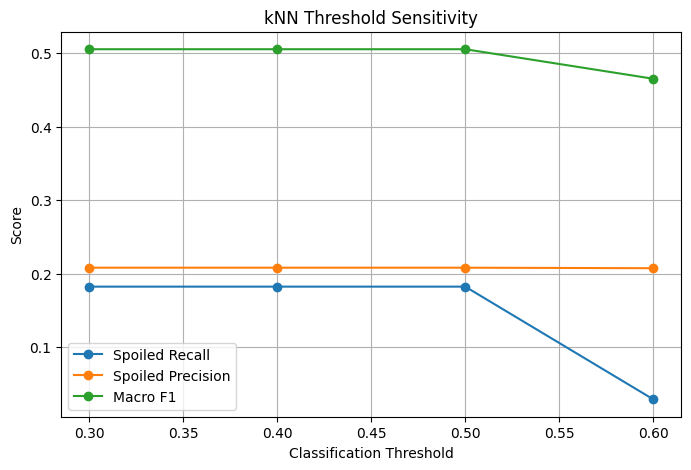

In [20]:
### 14.2 Threshold Sensitivity

# Threshold Sensitivity Analysis for kNN

thresholds = [0.30, 0.40, 0.50, 0.60]
threshold_results = []

# Calculate PR-AUC once because it does not depend on the threshold
knn_pr_auc = average_precision_score(y_val, y_scores)

for threshold in thresholds:

    # Convert probabilities into class predictions
    predictions = (y_scores >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average='macro'),
        "Spoiled Recall": recall_score(
            y_val, predictions, pos_label=1, zero_division=0
        ),
        "Spoiled Precision": precision_score(
            y_val, predictions, pos_label=1, zero_division=0
        ),
        "PR-AUC": knn_pr_auc
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


# Plot threshold sensitivity
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Spoiled Recall"],
    marker='o',
    label='Spoiled Recall'
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Spoiled Precision"],
    marker='o',
    label='Spoiled Precision'
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Macro F1"],
    marker='o',
    label='Macro F1'
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("kNN Threshold Sensitivity")
plt.legend()
plt.grid(True)
plt.show()

The threshold sensitivity experiment examined how different classification thresholds affected the kNN model's ability to identify spoiled products. At thresholds of 0.30, 0.40, and 0.50, the evaluation metrics remained approximately the same. However, increasing the threshold to 0.60 increased accuracy to 0.7858 while reducing spoiled-class recall to 0.0290. Macro F1 also decreased to 0.4650. PR-AUC remained unchanged because it is calculated using prediction probabilities rather than predictions at an individual threshold. These results demonstrate that increasing the threshold made the model more conservative when identifying spoiled products, but also caused it to miss more spoiled products.

### 14.3 Robustness Across Different k **Values**

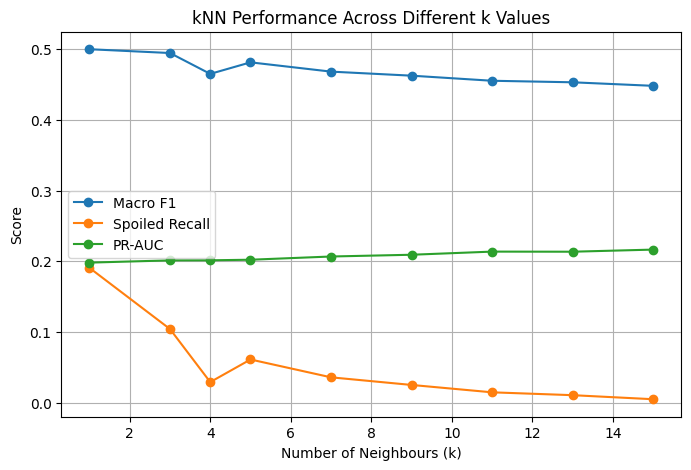

In [22]:
# Visualize kNN performance across different k values

knn_results_df = pd.DataFrame(results)

plt.figure(figsize=(8, 5))

plt.plot(knn_results_df["k"], knn_results_df["Macro F1"],
         marker='o', label='Macro F1')

plt.plot(knn_results_df["k"], knn_results_df["Recall (spoiled=1)"],
         marker='o', label='Spoiled Recall')

plt.plot(knn_results_df["k"], knn_results_df["PR-AUC"],
         marker='o', label='PR-AUC')

plt.xlabel("Number of Neighbours (k)")
plt.ylabel("Score")
plt.title("kNN Performance Across Different k Values")
plt.legend()
plt.grid(True)
plt.show()

We compared the results across different k values to determine whether the model's performance was stable or whether small changes in the number of neighbours caused significant differences in the evaluation metrics.

The robustness experiment evaluated how changing the number of neighbours affected kNN performance. The results show that Macro F1 and spoiled-class recall generally decreased as k increased, although there were some small variations. In contrast, PR-AUC generally increased, reaching its highest value of 0.2164 at k = 15. The highest Macro F1 and spoiled-class recall were achieved at k = 1. However, k = 1 can be more sensitive to individual neighbours and noise in the dataset. We selected k = 4 as our baseline because it provided a compromise between using a very small number of neighbours and a larger neighbourhood. However, its lower spoiled-class recall shows that it was not the strongest choice for identifying spoiled products. Compared with Logistic Regression and Random Forest, this experiment only evaluates kNN's sensitivity to its own hyperparameter and does not establish that kNN is the best-performing model overall.

## **<ins>Uncertainty</ins>**

### 15.1 Bootstrap Confidence Interval for PR-AUC


In [23]:
### 15.1 Bootstrap Confidence Interval for PR-AUC

y_true = np.array(y_val)
y_prob = np.array(y_scores)

rng = np.random.default_rng(42)
n_iterations = 1000
bootstrap_scores = []

for i in range(n_iterations):
    indices = rng.choice(len(y_true), size=len(y_true), replace=True)

    y_sample = y_true[indices]
    prob_sample = y_prob[indices]

    # Skip samples containing only one class
    if len(np.unique(y_sample)) < 2:
        continue

    score = average_precision_score(y_sample, prob_sample)
    bootstrap_scores.append(score)

if len(bootstrap_scores) > 0:
    lower_bound = np.percentile(bootstrap_scores, 2.5)
    upper_bound = np.percentile(bootstrap_scores, 97.5)

    original_score = average_precision_score(y_true, y_prob)

    print(f"Original Validation PR-AUC: {original_score:.4f}")
    print(f"95% Bootstrap Confidence Interval: ({lower_bound:.4f}, {upper_bound:.4f})")
else:
    print("Unable to calculate bootstrap confidence interval.")

Original Validation PR-AUC: 0.2013
95% Bootstrap Confidence Interval: (0.1942, 0.2092)


Bootstrap sampling was used to estimate uncertainty in the kNN model's validation PR-AUC. A total of 1,000 bootstrap samples were generated, and the 2.5th and 97.5th percentiles were used to calculate a 95% confidence interval. The resulting confidence interval was 0.1942 to 0.2092. This interval provides an estimate of the variation in PR-AUC due to sampling uncertainty. However, it does not guarantee that the model will achieve the same performance on future data.

### 15.2 Feature Selection Uncertainty

The selection of features introduces uncertainty because some columns were removed due to potential data leakage. Although class mean comparisons helped identify differences between spoiled and non-spoiled products, they cannot determine whether a feature is safe to use for prediction. The main consideration is whether the information would be available when the prediction is made. For example, features such as units_wasted, waste_cost, and profit describe outcomes that occur after spoilage and should remain excluded. Other features should be reviewed based on their definitions and availability at prediction time. This means that the final model's performance may depend on which features are considered appropriate for use.

These feature selection decisions can affect all three models because each model relies on the available input features to make predictions. Therefore, changes in the selected features may lead to different performance results across kNN, Logistic Regression, and Random Forest.

  ### 15.3 Limitations of the Evaluation
  
  Our evaluation also has uncertainty because the dataset is synthetic and may not fully represent real grocery store conditions. Actual spoilage can be affected by factors that are not included in the dataset, such as differences in supplier practices, transportation conditions, store management, and unexpected temperature changes. Additionally, our chronological split evaluates the models on a later portion of the same dataset, but future data may contain patterns that differ from the training and validation periods. Another limitation is that the bootstrap method treats validation observations as independent, even though transactions may have time-related patterns. Therefore, the confidence interval may not fully capture temporal uncertainty. The class imbalance also makes it more difficult to evaluate spoilage detection reliably. Therefore, the validation results should be treated as estimates rather than guaranteed real-world performance.

## **<ins>Experiment Log</ins>**

## **<ins>Conclusion</ins>**